In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import cross_validate, cross_val_predict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv('../../datasets/balanceados/dataset_total_balanceado.csv')

df.head()

,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Inbound,Label
0,1,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0
1,2,2,62.0,318.0,31.0,31.0,31.0,0.0,159.0,159.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,2,0,2944.0,0.0,1472.0,1472.0,1472.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1
3,3,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0
4,2,0,868.0,0.0,434.0,434.0,434.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 63 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Fwd Packet Length Max        104802 non-null  float64
 5   Fwd Packet Length Min        104802 non-null  float64
 6   Fwd Packet Length Mean       104802 non-null  float64
 7   Fwd Packet Length Std        104802 non-null  float64
 8   Bwd Packet Length Max        104802 non-null  float64
 9   Bwd Packet Length Min        104802 non-null  float64
 10  Bwd Packet Length Mean       104802 non-null  float64
 11  Bwd Packet Length Std        104802 non-null  float64
 12  Flow Bytes/s                 104802 non-null  float64
 13  Flow Packe

Decision Tree

In [4]:
x = df.drop(columns=['Label'])
y = df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)
x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
x_treino_scaled = scaler.fit_transform(x_treino)
x_teste_scaled = scaler.transform(x_teste)

modelo_dt = tree.DecisionTreeClassifier(max_depth=8, random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
raw_matriz = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    raw_matriz, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')

## Quando podo a 8 ramos, a arvore atinge seu melhor desempenho ###


Acurácia no conjunto de treino: 0.9999
Acurácia:  99.9761
Precisão:  99.9760
Recall:    99.9763
F1-Score:  99.9761

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.99%                0.01%
Real: 1 (Ataque)                0.04%               99.96%


In [5]:
modelo_dt_kfold = make_pipeline(StandardScaler(), tree.DecisionTreeClassifier(max_depth=9, random_state=42))
metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

y_pred_kfold_dt = cross_val_predict(modelo_dt_kfold, x, y, cv=5)
matriz_dt2 = confusion_matrix(y, y_pred_kfold_dt)

resultados_kfold_dt = cross_validate(modelo_dt_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_dt = resultados_kfold_dt['test_accuracy'].mean()
precisao_kfold_dt = resultados_kfold_dt['test_precision_macro'].mean()
recall_kfold_dt = resultados_kfold_dt['test_recall_macro'].mean()
f1_kfold_dt = resultados_kfold_dt['test_f1_macro'].mean()

matriz_confusao_dt2 = pd.DataFrame(
    matriz_dt2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt2 = matriz_confusao_dt2.div(matriz_confusao_dt2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_dt*100):.4f}")
print(f"Precisão:  {(precisao_kfold_dt*100):.4f}")
print(f"Recall:    {(recall_kfold_dt*100):.4f}")
print(f"F1-Score:  {(f1_kfold_dt*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Kfold):")
print((( matriz_normalizada_dt2)*100).round(2).astype(str) + '%')

Acurácia:  99.9676
Precisão:  99.9676
Recall:    99.9676
F1-Score:  99.9676

                       MATRIZ DE CONFUSÃO(DT- Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.98%                0.02%
Real: 1 (Ataque)                0.05%               99.95%


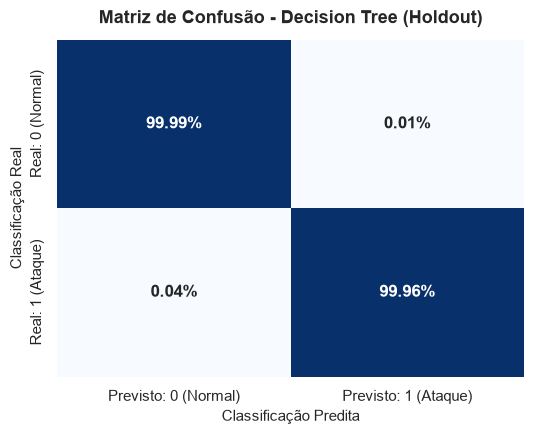

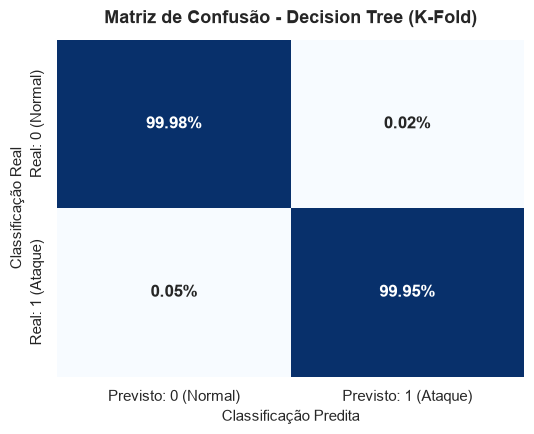

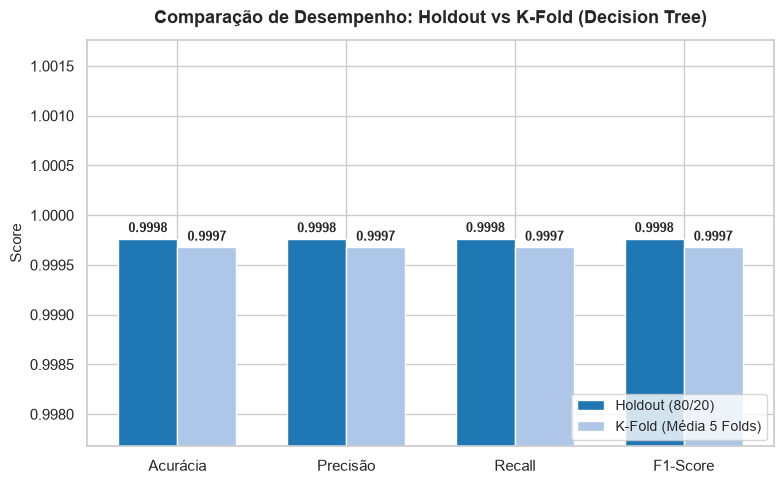

In [6]:
sns.set_theme(style="whitegrid")

matriz_pct_dt1 = matriz_normalizada_dt1.values * 100
labels_dt1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_dt1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_dt1, annot=labels_dt1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Decision Tree (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_dt2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Decision Tree (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia, precisao, recall, f1]
valores_kfold = [
    resultados_kfold_dt['test_accuracy'].mean(),
    resultados_kfold_dt['test_precision_macro'].mean(),
    resultados_kfold_dt['test_recall_macro'].mean(),
    resultados_kfold_dt['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color='#1f77b4')
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color='#aec7e8')

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (Decision Tree)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

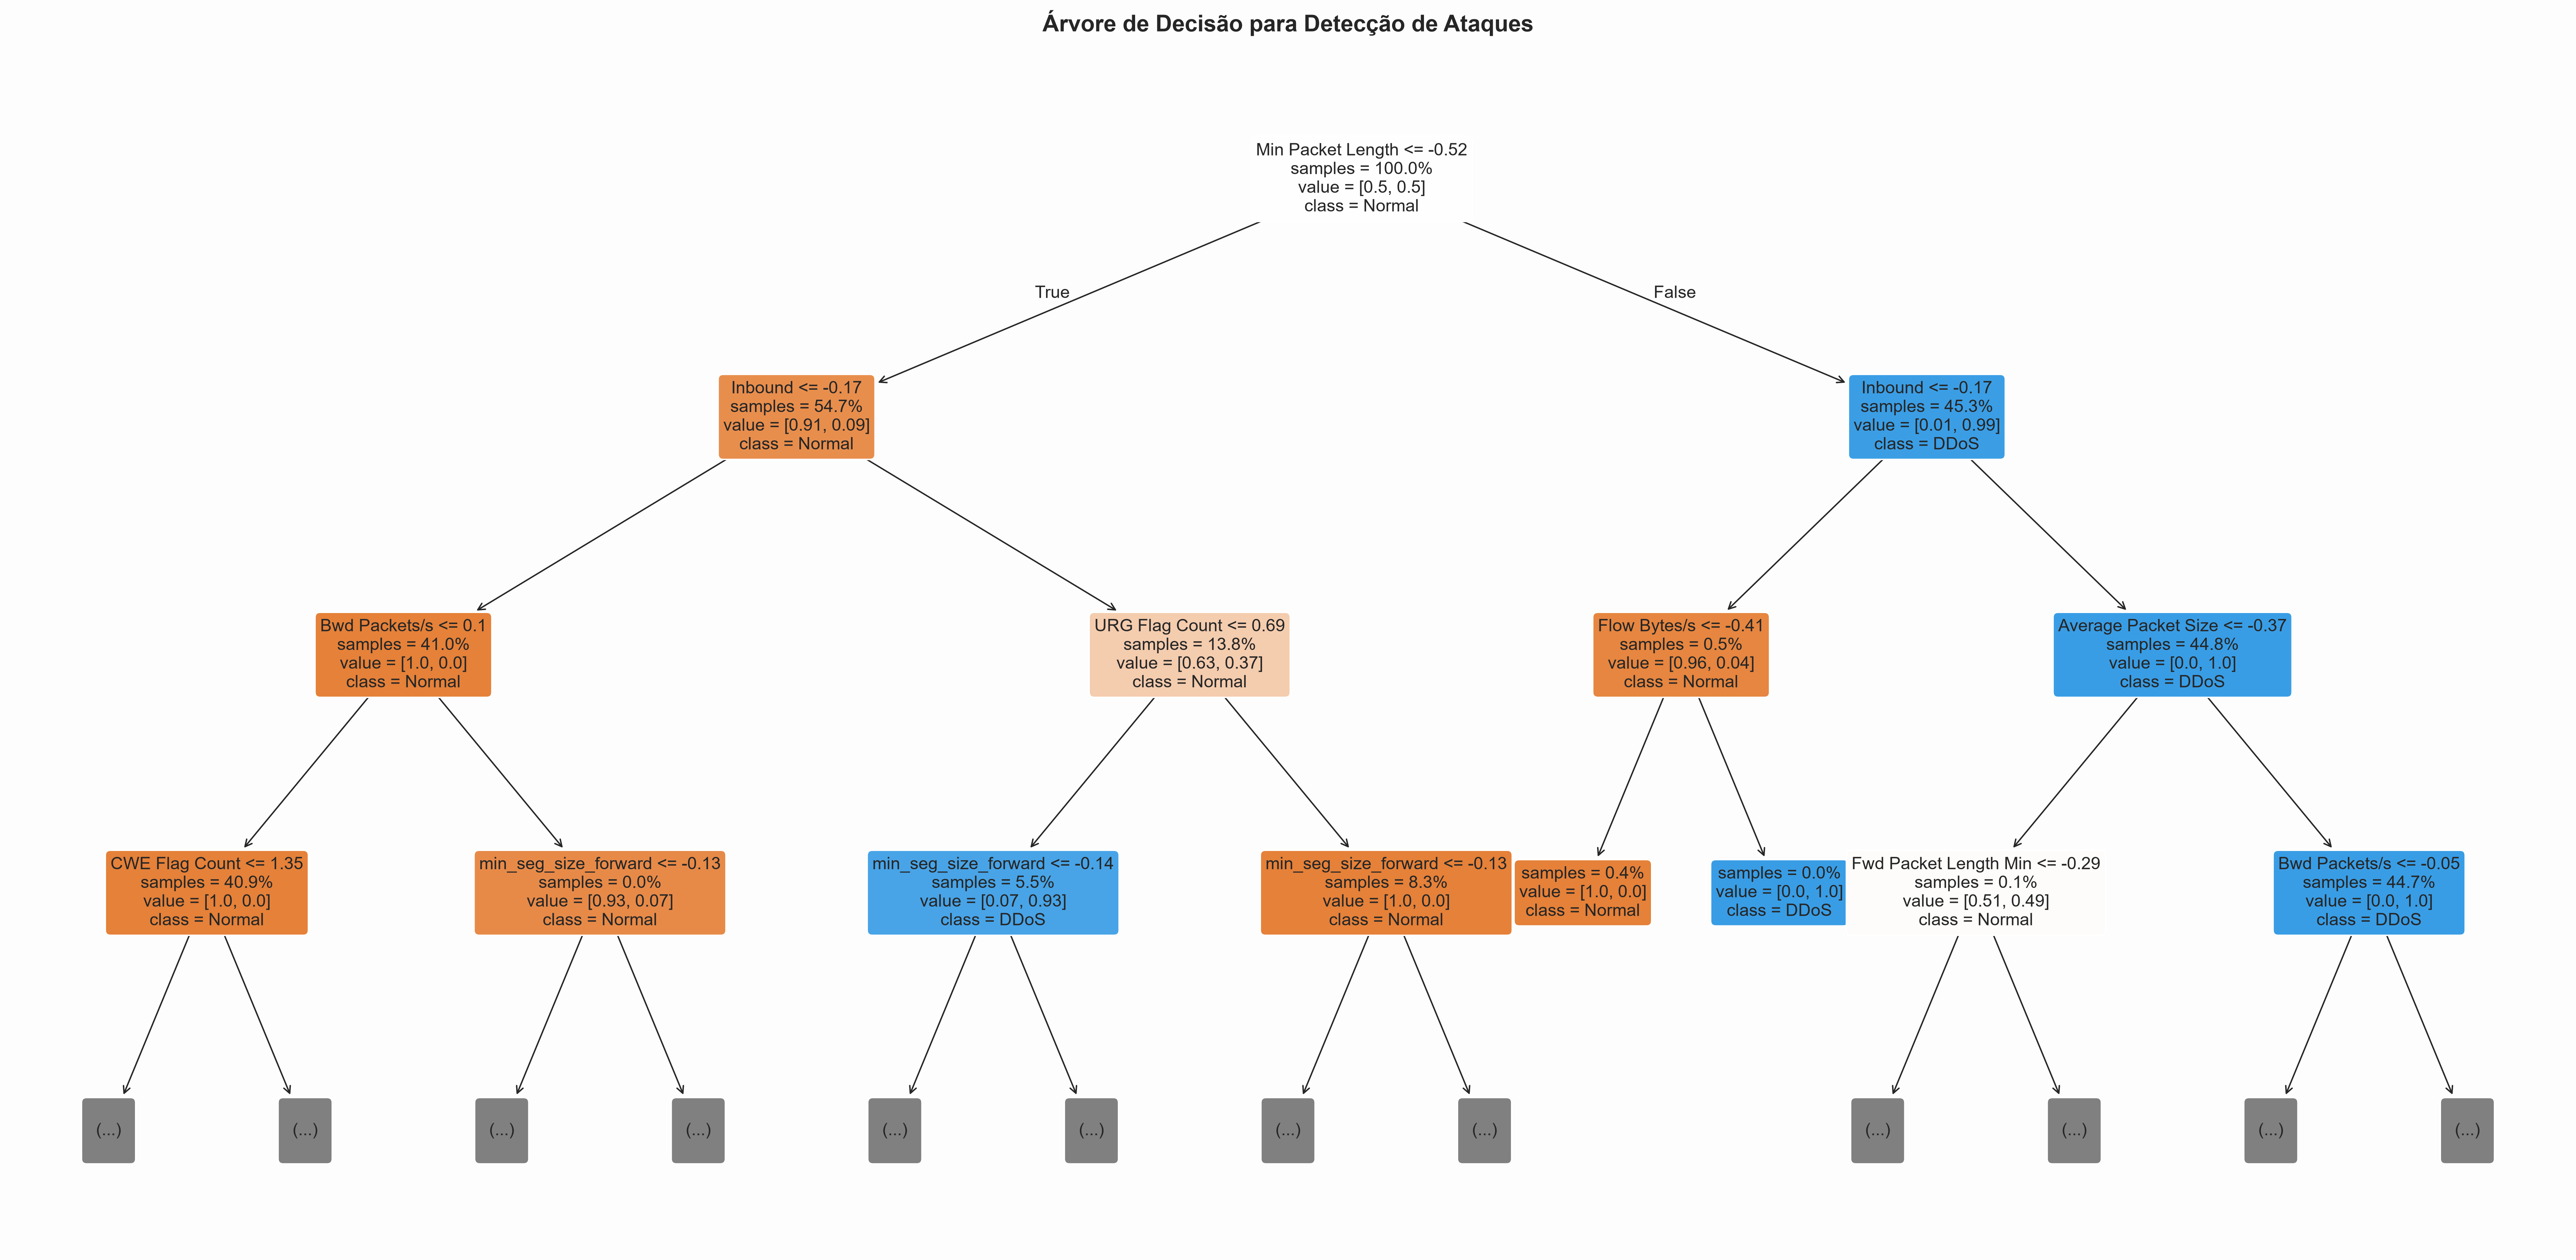

In [7]:
fig, ax = plt.subplots(figsize=(32, 15), dpi=310)
fig.patch.set_facecolor('#fdfdfd') 

tree.plot_tree(
    modelo_dt, 
    max_depth=3, ## A maior acuracia foi gerada com 8 ramificações, mas para a plotagem será limitada a 3 para melhor vizualização.
    feature_names=x.columns.tolist(),
    filled=True, 
    class_names=['Normal', 'DDoS'],
    fontsize=12,
    rounded=True, 
    precision=2,
    impurity=False,
    proportion=True
)

ax.axis('off') 
plt.title("Árvore de Decisão para Detecção de Ataques", fontsize=16, fontweight='bold', pad=20)

plt.show()

Random Forest

In [8]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 1.0000
Acurácia:  99.9571
Precisão:  99.9570
Recall:    99.9571
F1-Score:  99.9571

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.96%                0.04%
Real: 1 (Ataque)                0.05%               99.95%


In [9]:
modelo_rf_kfold = make_pipeline(StandardScaler(),RandomForestClassifier(random_state=42, n_jobs=-1))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_rf = cross_validate(modelo_rf_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_rf = resultados_kfold_rf['test_accuracy'].mean()
precisao_kfold_rf = resultados_kfold_rf['test_precision_macro'].mean()
recall_kfold_rf = resultados_kfold_rf['test_recall_macro'].mean()
f1_kfold_rf = resultados_kfold_rf['test_f1_macro'].mean()

y_pred_kfold_rf = cross_val_predict(modelo_rf_kfold, x, y, cv=5)
matriz_rf2 = confusion_matrix(y, y_pred_kfold_rf)

matriz_confusao_rf2 = pd.DataFrame(
    matriz_rf2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf2 = matriz_confusao_rf2.div(matriz_confusao_rf2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_rf*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_rf*100):.4f}%")
print(f"Recall:    {(recall_kfold_rf*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_rf*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (RF - Kfold):")
print(((matriz_normalizada_rf2)*100).round(2).astype(str) + '%')

Acurácia:  99.9714%
Precisão:  99.9714%
Recall:    99.9714%
F1-Score:  99.9714%

                   MATRIZ DE CONFUSÃO (RF - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.98%                0.02%
Real: 1 (Ataque)                0.04%               99.96%


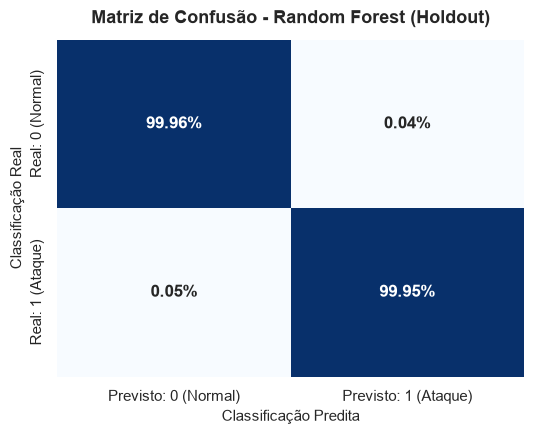

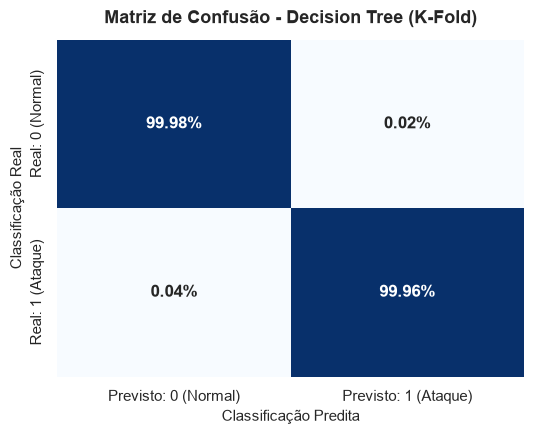

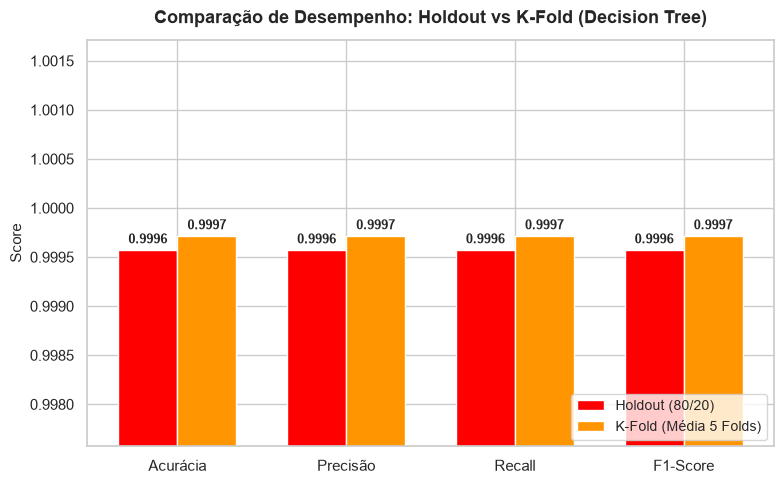

In [10]:
matriz_pct_rf1 = matriz_normalizada_rf1.values * 100
labels_rf1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_rf1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_rf1, annot=labels_rf1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Random Forest (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_rf2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Decision Tree (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_rf, precisao_rf, recall_rf, f1_rf]
valores_kfold = [
    resultados_kfold_rf['test_accuracy'].mean(),
    resultados_kfold_rf['test_precision_macro'].mean(),
    resultados_kfold_rf['test_recall_macro'].mean(),
    resultados_kfold_rf['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#FF0000")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#ff9500")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (Decision Tree)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

MLP - Rede Neural

In [11]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9996
Acurácia:  99.9475
Precisão:  99.9476
Recall:    99.9475
F1-Score:  99.9475

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.94%                0.06%
Real: 1 (Ataque)                0.05%               99.95%


In [12]:
modelo_mlp_kfold = make_pipeline(StandardScaler(),MLPClassifier(random_state=42, max_iter=300))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_mlp = cross_validate(modelo_mlp_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_mlp = resultados_kfold_mlp['test_accuracy'].mean()
precisao_kfold_mlp = resultados_kfold_mlp['test_precision_macro'].mean()
recall_kfold_mlp = resultados_kfold_mlp['test_recall_macro'].mean()
f1_kfold_mlp = resultados_kfold_mlp['test_f1_macro'].mean()

y_pred_kfold_mlp = cross_val_predict(modelo_mlp_kfold, x, y, cv=5)
matriz_mlp2 = confusion_matrix(y, y_pred_kfold_mlp)

matriz_confusao_mlp2 = pd.DataFrame(
    matriz_mlp2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp2 = matriz_confusao_mlp2.div(matriz_confusao_mlp2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_mlp*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_mlp*100):.4f}%")
print(f"Recall:    {(recall_kfold_mlp*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_mlp*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (MLP - Kfold):")
print(((matriz_normalizada_mlp2)*100).round(2).astype(str) + '%')


Acurácia:  99.9323%
Precisão:  99.9323%
Recall:    99.9323%
F1-Score:  99.9323%

                   MATRIZ DE CONFUSÃO (MLP - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.92%                0.08%
Real: 1 (Ataque)                0.06%               99.94%


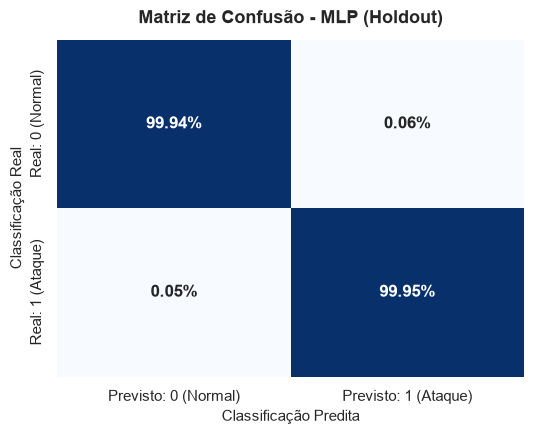

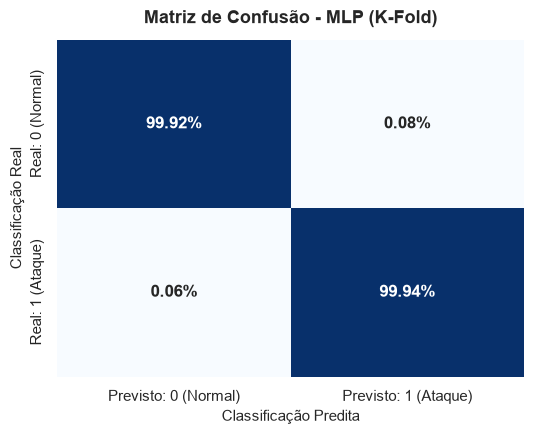

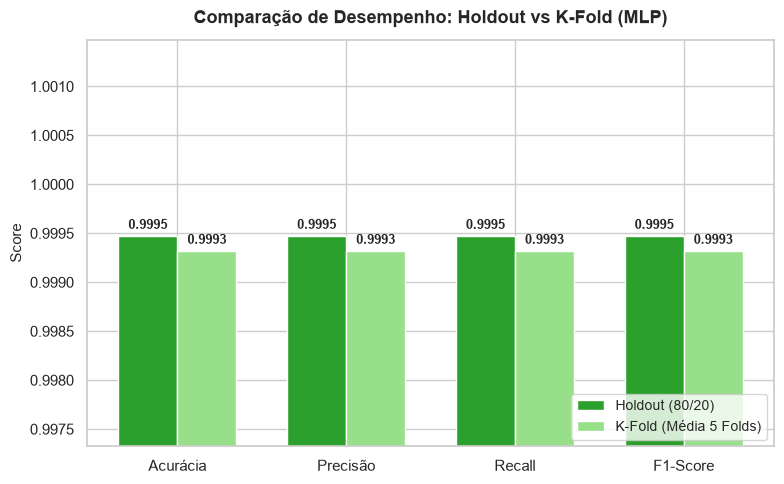

In [13]:
matriz_pct_mlp1 = matriz_normalizada_mlp1.values * 100
labels_mlp1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_mlp1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_mlp1, annot=labels_mlp1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - MLP (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_mlp2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - MLP (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_mlp, precisao_mlp, recall_mlp, f1_mlp]
valores_kfold = [
    resultados_kfold_mlp['test_accuracy'].mean(),
    resultados_kfold_mlp['test_precision_macro'].mean(),
    resultados_kfold_mlp['test_recall_macro'].mean(),
    resultados_kfold_mlp['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (MLP)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

SVM

In [14]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9979
Acurácia:  99.8664
Precisão:  99.8673
Recall:    99.8657
F1-Score:  99.8664

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.77%                0.23%
Real: 1 (Ataque)                0.04%               99.96%


In [15]:
modelo_svm_kfold = make_pipeline(StandardScaler(),LinearSVC(random_state=42, max_iter=2000, dual=False))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_svm = cross_validate(modelo_svm_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_svm = resultados_kfold_svm['test_accuracy'].mean()
precisao_kfold_svm = resultados_kfold_svm['test_precision_macro'].mean()
recall_kfold_svm = resultados_kfold_svm['test_recall_macro'].mean()
f1_kfold_svm = resultados_kfold_svm['test_f1_macro'].mean()

y_pred_kfold_svm = cross_val_predict(modelo_svm_kfold, x, y, cv=5)
matriz_svm2 = confusion_matrix(y, y_pred_kfold_svm)

matriz_confusao_svm2 = pd.DataFrame(
    matriz_svm2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm2 = matriz_confusao_svm2.div(matriz_confusao_svm2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_svm*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_svm*100):.4f}%")
print(f"Recall:    {(recall_kfold_svm*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_svm*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (SVM - Kfold):")
print(((matriz_normalizada_svm2)*100).round(2).astype(str) + '%')


Acurácia:  99.7987%
Precisão:  99.7991%
Recall:    99.7987%
F1-Score:  99.7987%

                   MATRIZ DE CONFUSÃO (SVM - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.66%                0.34%
Real: 1 (Ataque)                0.07%               99.93%


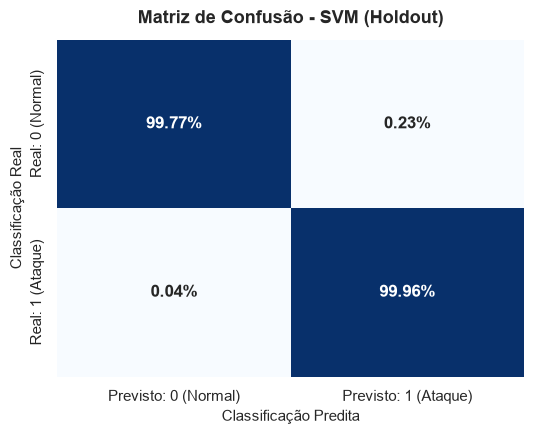

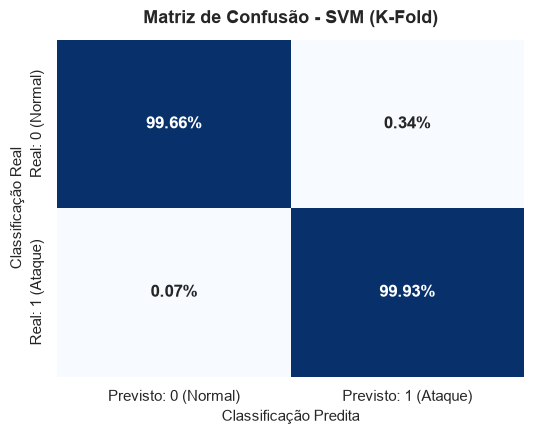

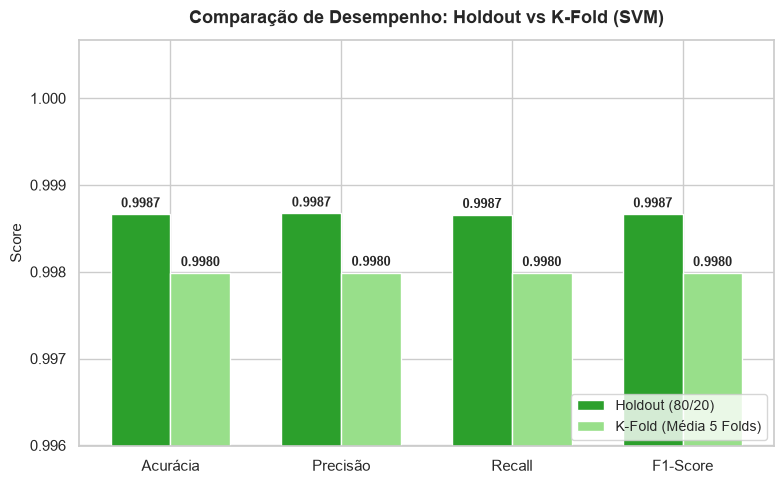

In [16]:
matriz_pct_svm1 = matriz_normalizada_svm1.values * 100
labels_svm1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_svm1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_svm1, annot=labels_svm1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - SVM (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_svm2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - SVM (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_svm, precisao_svm, recall_svm, f1_svm]
valores_kfold = [
    resultados_kfold_svm['test_accuracy'].mean(),
    resultados_kfold_svm['test_precision_macro'].mean(),
    resultados_kfold_svm['test_recall_macro'].mean(),
    resultados_kfold_svm['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (SVM)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

KNN

In [30]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9996
Acurácia:  99.9237%
Precisão:  99.9233%
Recall:    99.9240%
F1-Score:  99.9237%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.97%                0.03%
Real: 1 (Ataque)                0.12%               99.88%


In [18]:
modelo_knn_kfold = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

y_pred_kfold_knn = cross_val_predict(modelo_knn_kfold, x, y, cv=5)
matriz_knn2 = confusion_matrix(y, y_pred_kfold_knn)

resultados_kfold_knn = cross_validate(modelo_knn_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_knn = resultados_kfold_knn['test_accuracy'].mean()
precisao_kfold_knn = resultados_kfold_knn['test_precision_macro'].mean()
recall_kfold_knn = resultados_kfold_knn['test_recall_macro'].mean()
f1_kfold_knn = resultados_kfold_knn['test_f1_macro'].mean()

matriz_confusao_knn2 = pd.DataFrame(
    matriz_knn2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn2 = matriz_confusao_knn2.div(matriz_confusao_knn2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_knn*100):.4f}")
print(f"Precisão:  {(precisao_kfold_knn*100):.4f}")
print(f"Recall:    {(recall_kfold_knn*100):.4f}")
print(f"F1-Score:  {(f1_kfold_knn*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(KNN- Kfold):")
print(((matriz_normalizada_knn2)*100).round(2).astype(str) + '%')

Acurácia:  99.9294
Precisão:  99.9294
Recall:    99.9294
F1-Score:  99.9294

                       MATRIZ DE CONFUSÃO(KNN- Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.96%                0.04%
Real: 1 (Ataque)                 0.1%                99.9%


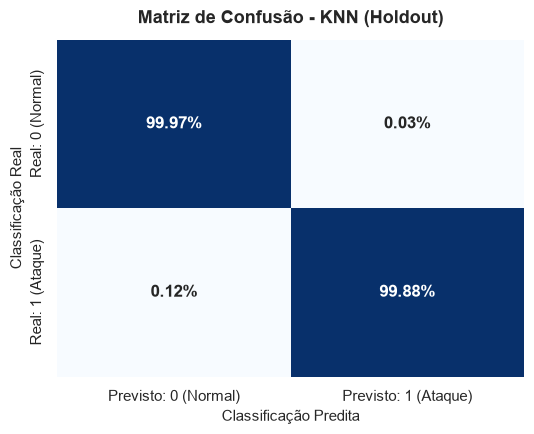

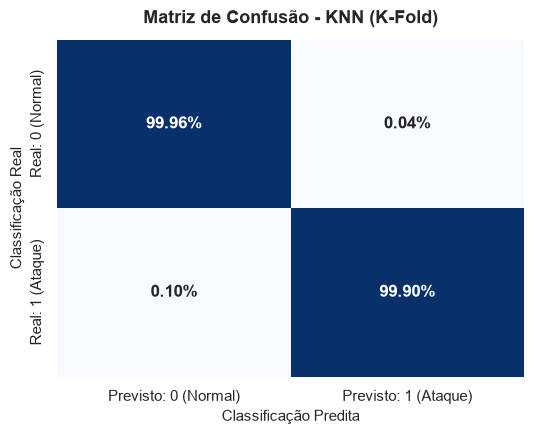

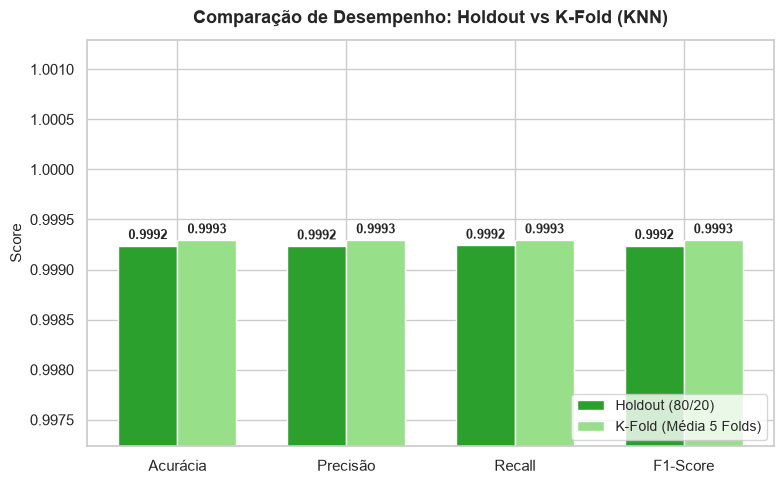

In [19]:
matriz_pct_knn1 = matriz_normalizada_knn1.values * 100
labels_knn1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_knn1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_knn1, annot=labels_knn1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - KNN (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_knn2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - KNN (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_knn, precisao_knn, recall_knn, f1_knn]
valores_kfold = [
    resultados_kfold_knn['test_accuracy'].mean(),
    resultados_kfold_knn['test_precision_macro'].mean(),
    resultados_kfold_knn['test_recall_macro'].mean(),
    resultados_kfold_knn['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (KNN)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

XgBOOST

In [20]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 1.0000
Acurácia:  99.9571
Precisão:  99.9571
Recall:    99.9570
F1-Score:  99.9571

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.95%                0.05%
Real: 1 (Ataque)                0.04%               99.96%


In [21]:
modelo_xgb_kfold = make_pipeline(
    StandardScaler(),
    xgb.XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
)

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_xgb = cross_validate(modelo_xgb_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_xgb = resultados_kfold_xgb['test_accuracy'].mean()
precisao_kfold_xgb = resultados_kfold_xgb['test_precision_macro'].mean()
recall_kfold_xgb = resultados_kfold_xgb['test_recall_macro'].mean()
f1_kfold_xgb = resultados_kfold_xgb['test_f1_macro'].mean()

y_pred_kfold_xgb = cross_val_predict(modelo_xgb_kfold, x, y, cv=5)
matriz_xgb2 = confusion_matrix(y, y_pred_kfold_xgb)

matriz_confusao_xgb2 = pd.DataFrame(
    matriz_xgb2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb2 = matriz_confusao_xgb2.div(matriz_confusao_xgb2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_xgb*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_xgb*100):.4f}%")
print(f"Recall:    {(recall_kfold_xgb*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_xgb*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (XGB - Kfold):")
print(((matriz_normalizada_xgb2)*100).round(2).astype(str) + '%')

Acurácia:  99.9666%
Precisão:  99.9666%
Recall:    99.9666%
F1-Score:  99.9666%

                   MATRIZ DE CONFUSÃO (XGB - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               99.97%                0.03%
Real: 1 (Ataque)                0.04%               99.96%


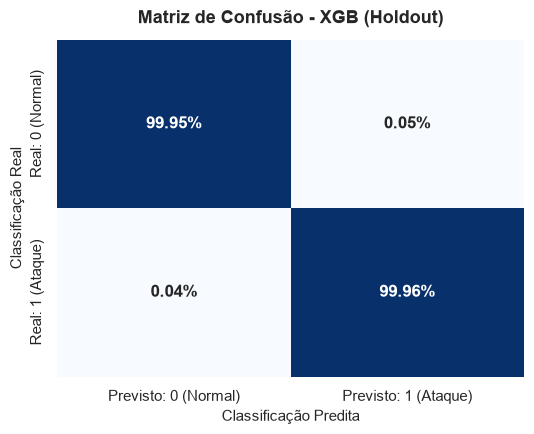

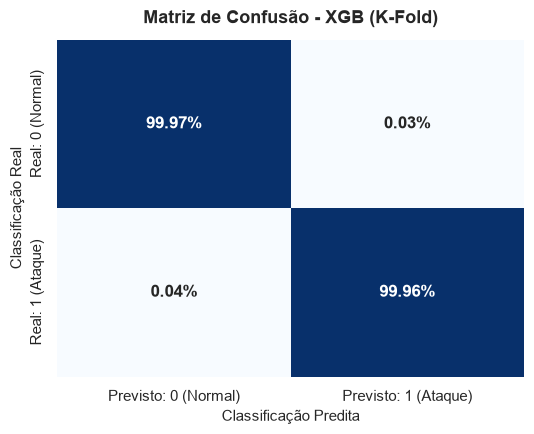

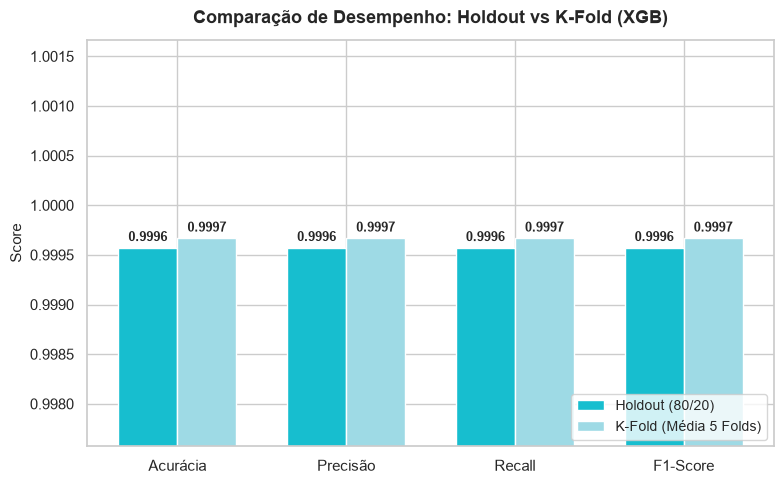

In [22]:
matriz_pct_xgb1 = matriz_normalizada_xgb1.values * 100
labels_xgb1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_xgb1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_xgb1, annot=labels_xgb1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - XGB (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_xgb2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - XGB (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_xgb, precisao_xgb, recall_xgb, f1_xgb]
valores_kfold = [
    resultados_kfold_xgb['test_accuracy'].mean(),
    resultados_kfold_xgb['test_precision_macro'].mean(),
    resultados_kfold_xgb['test_recall_macro'].mean(),
    resultados_kfold_xgb['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#17becf")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#9edae5")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (XGB)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

IA explicavel - SHAP

In [23]:
import shap

c:\Users\jvesc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [24]:
scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)


Decision Tree

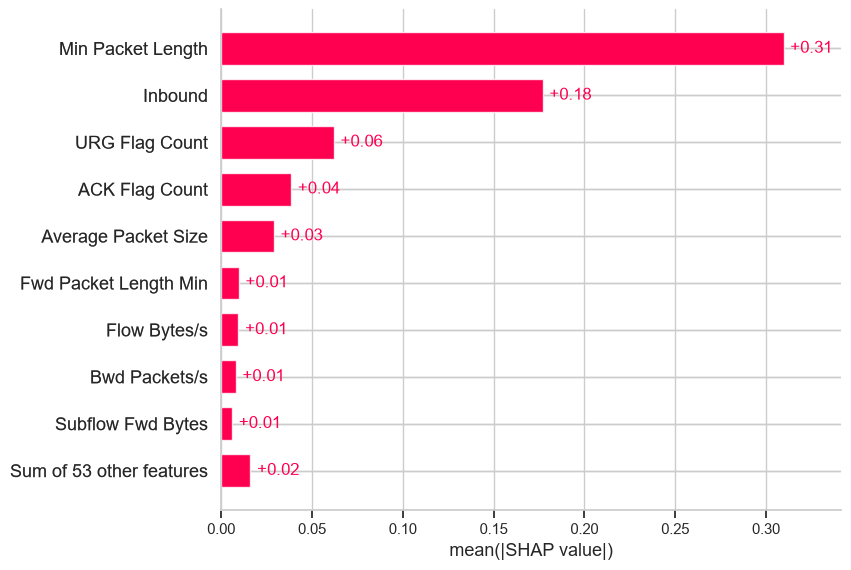

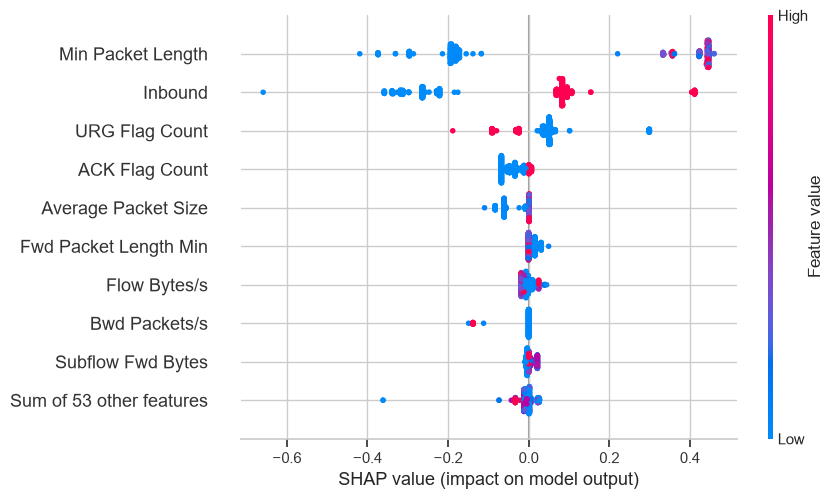

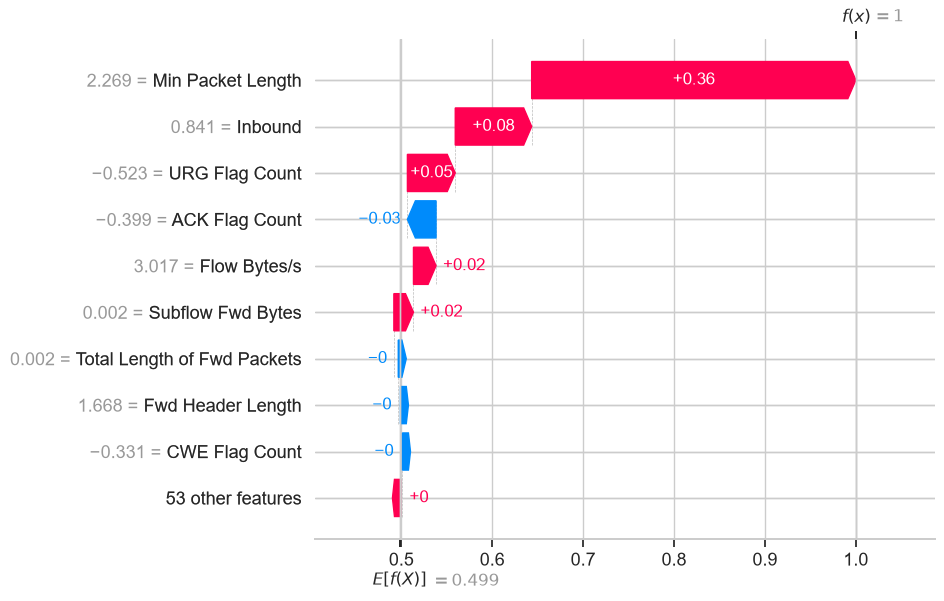

In [25]:
explainer = shap.TreeExplainer(modelo_dt)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values[:, :, 1])
shap.plots.beeswarm(shap_values[:, :, 1])
shap.plots.waterfall(shap_values[0, :, 1])

Random Forest

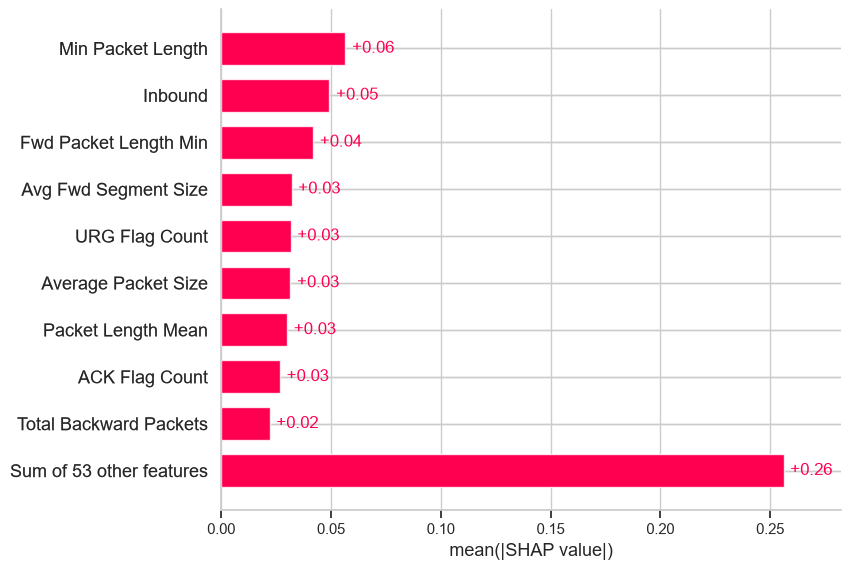

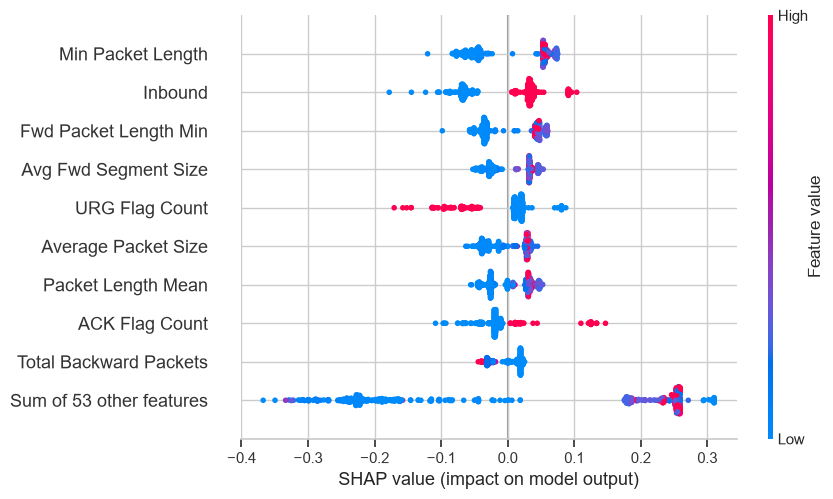

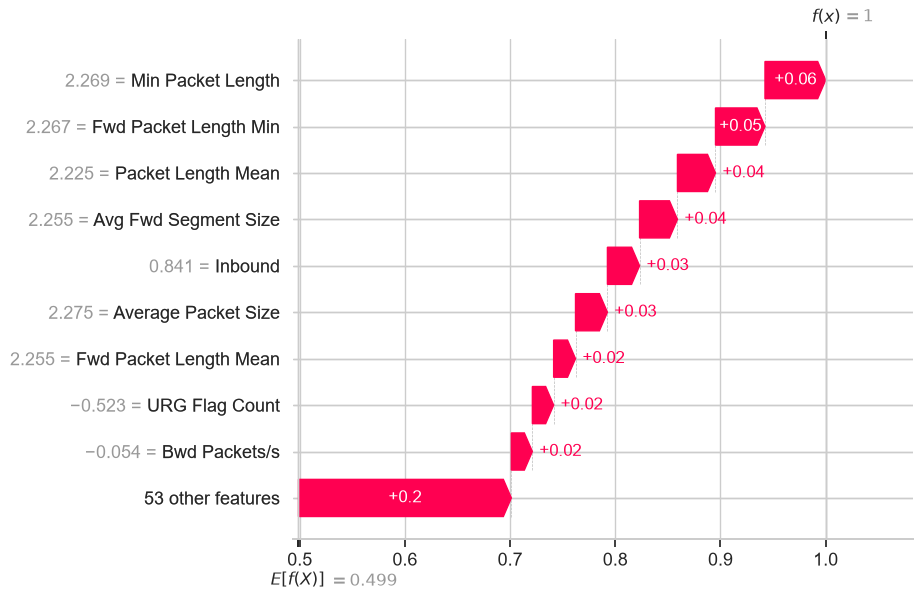

In [26]:
explainer = shap.TreeExplainer(modelo_rf)
shap_values = explainer(amostra_500)        

shap.plots.bar(shap_values[:, :, 1])
shap.plots.beeswarm(shap_values[:, :, 1])
shap.plots.waterfall(shap_values[0, :, 1])

XGBoost

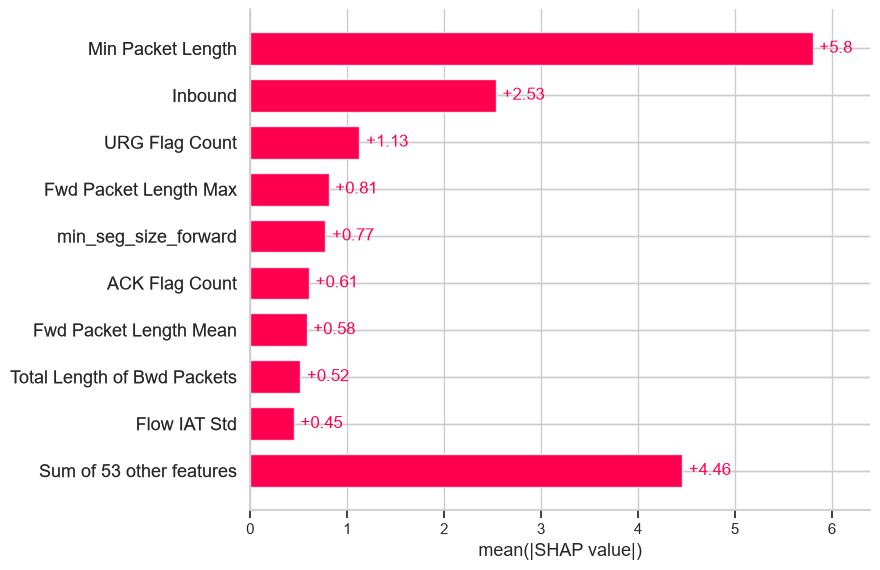

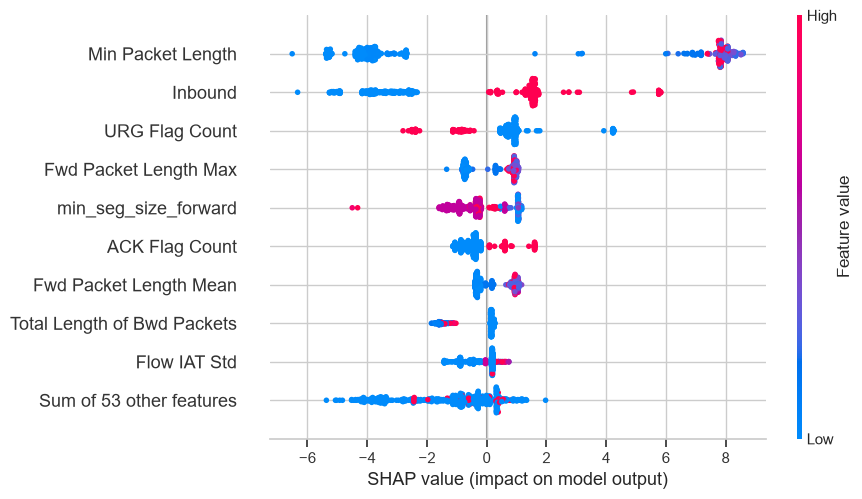

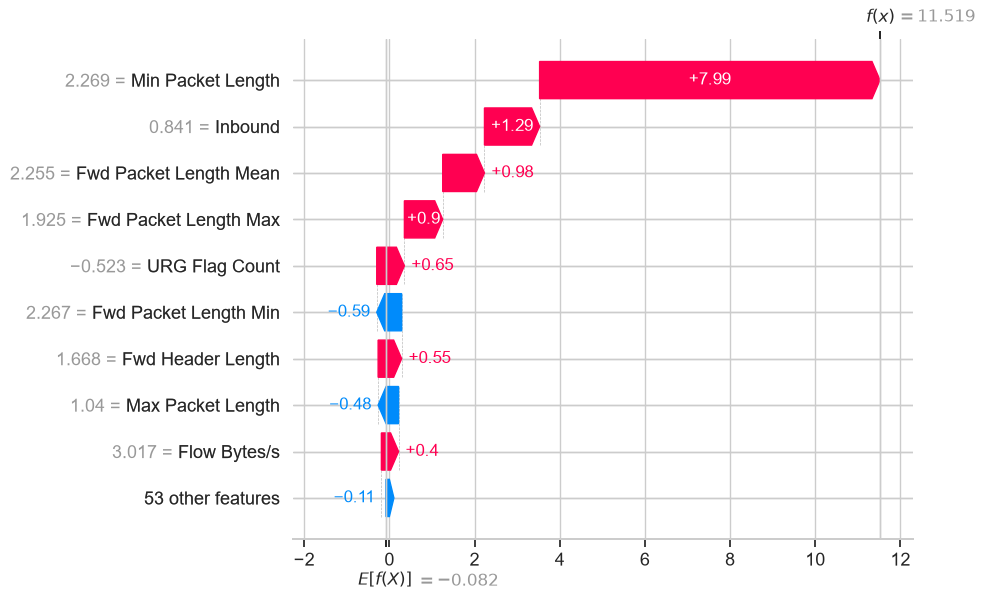

In [27]:
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)
shap.plots.beeswarm(shap_values)
shap.plots.waterfall(shap_values[0])

SVM

Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


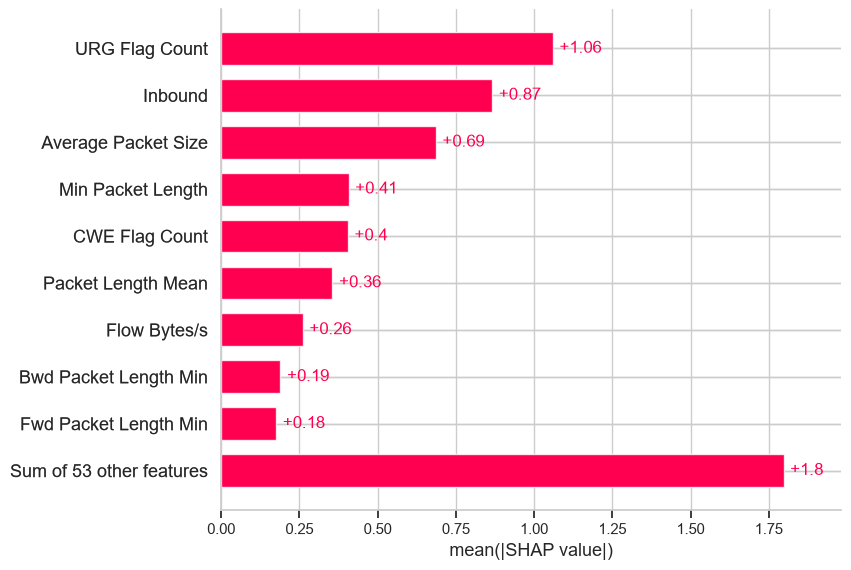

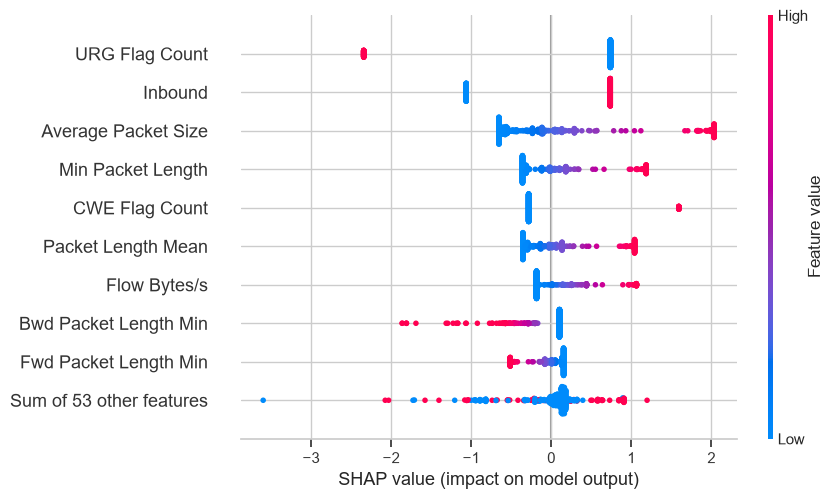

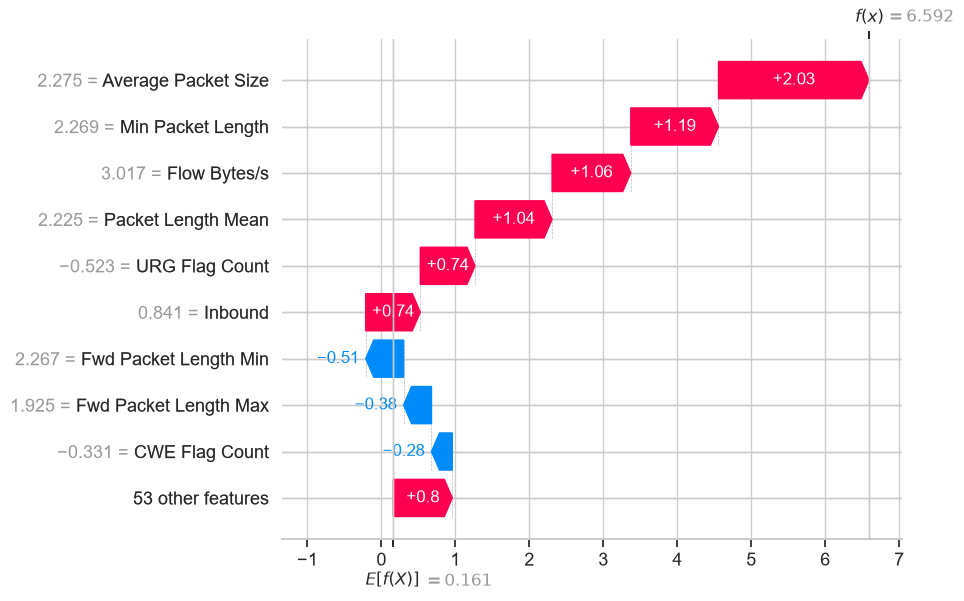

In [28]:
explainer = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values = explainer(amostra_500)

shap.plots.bar(shap_values)                   
shap.plots.beeswarm(shap_values)              
shap.plots.waterfall(shap_values[0])

KNN

PermutationExplainer explainer: 101it [04:28,  2.83s/it]                         


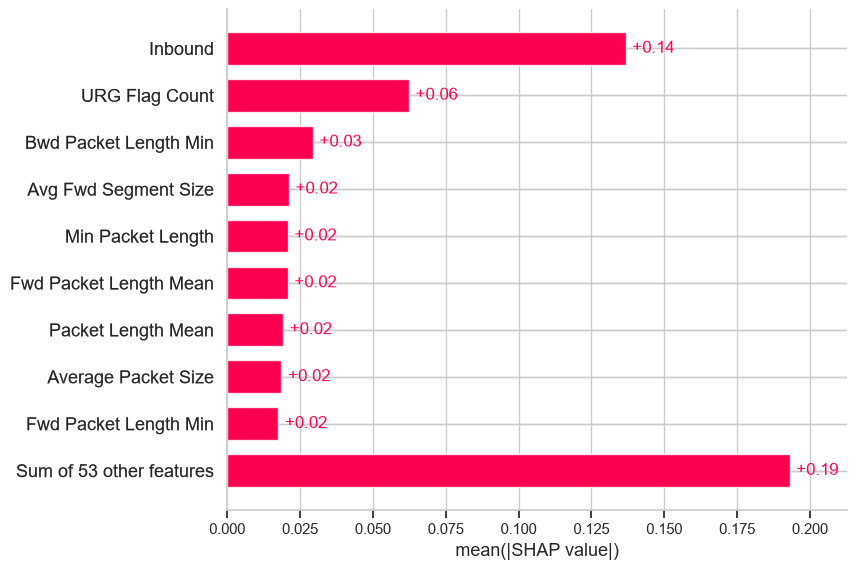

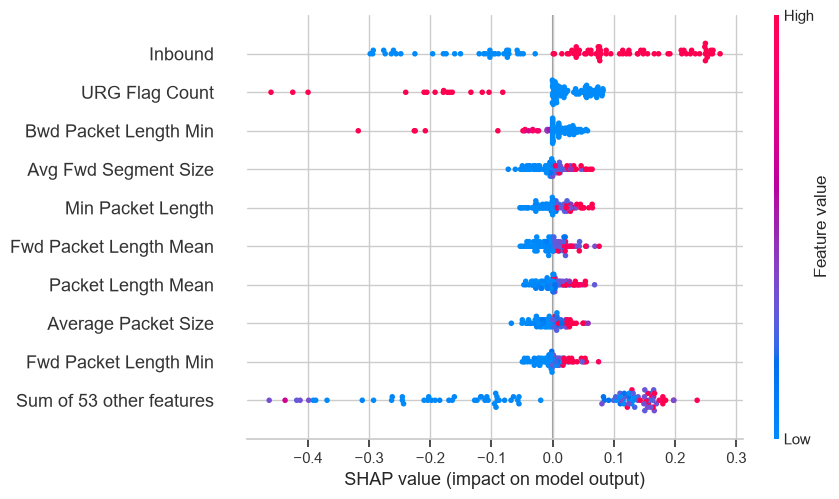

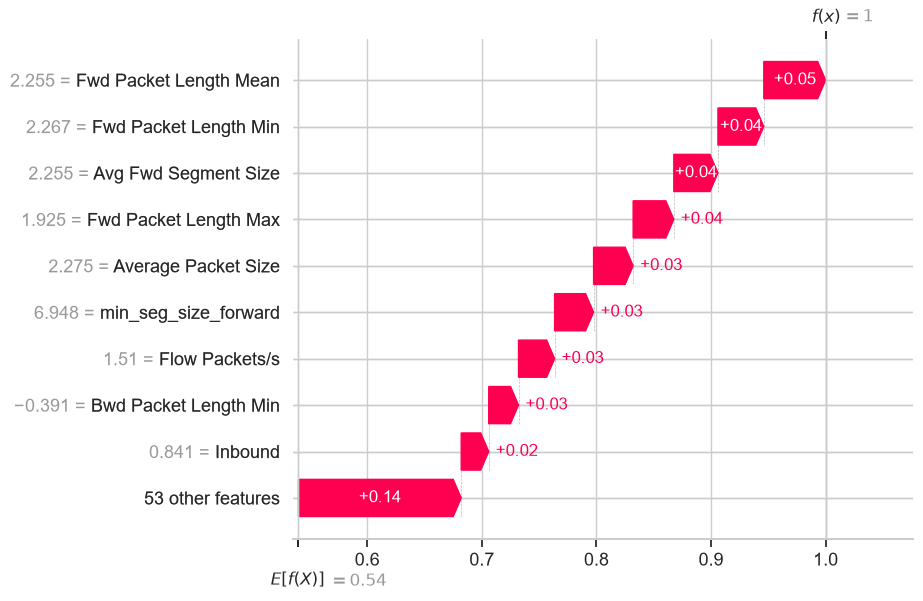

In [31]:
explainer = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))

shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:,:, 1])
shap.plots.beeswarm(shap_values[:, :, 1])
shap.plots.waterfall(shap_values[0, :, 1])

MLP

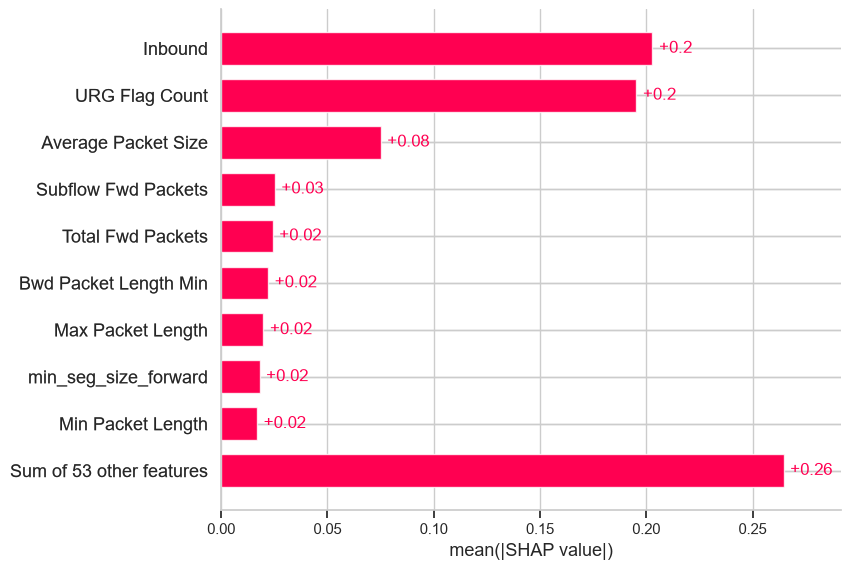

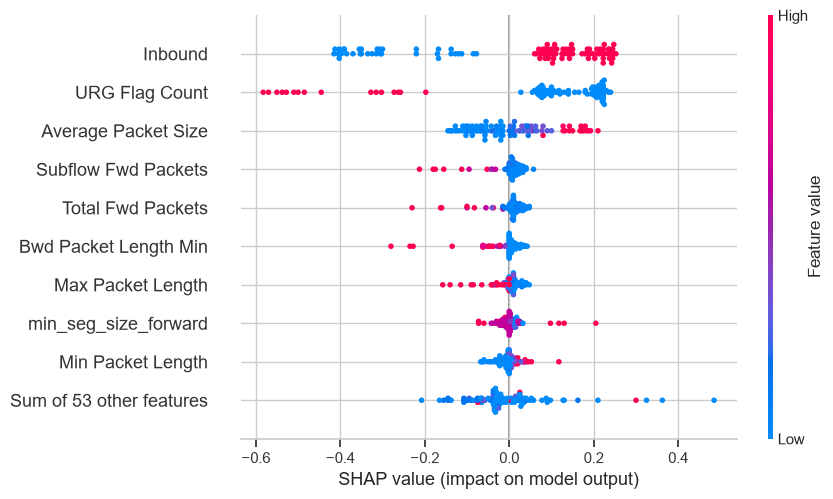

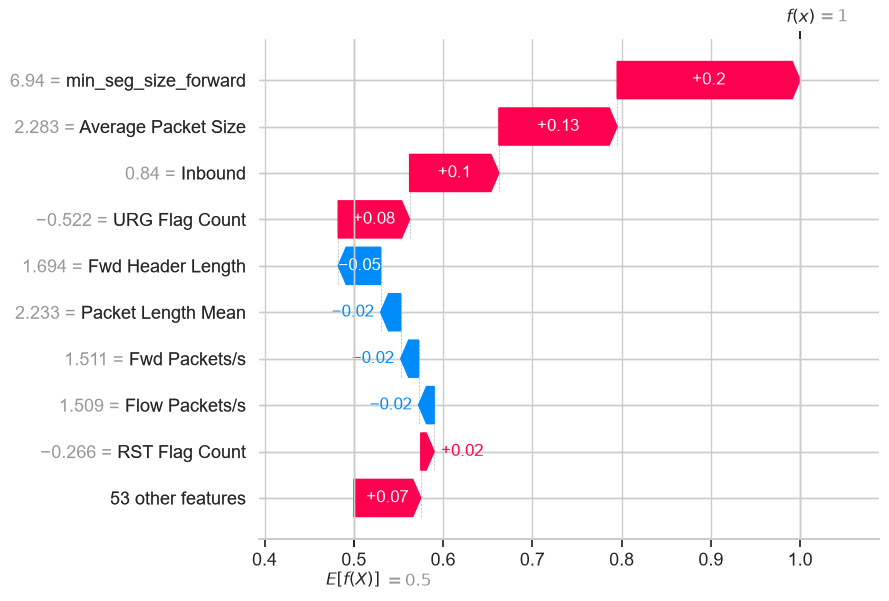

In [ ]:
explainer = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))

shap_values = explainer(amostra_100)

shap.plots.bar(shap_values[:, :, 1])
shap.plots.beeswarm(shap_values[:, :, 1])
shap.plots.waterfall(shap_values[0, :, 1])